# Standard Quantum Phase Estimation (QPE) — CUDA-Q

**Primitive:** Quantum Phase Estimation (standard / textbook form) — matched to the companion Qiskit notebook.

## Setup
- N_COUNTING: 3, N_TARGET: 1 (total qubits = 4)
- Unitary U: R1(λ) phase gate, λ = π/4 (equivalent to Qiskit's P(λ) / T gate)
- Eigenstate: |1⟩ on the target qubit
- THETA: 1/8, SHOTS: 10000, SEED: 42
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring.
  ⚠️ CUDA-Q's `get_state()` and `sample()` index qubit 0 as the **most-significant (leftmost)**
  bit — the opposite of Qiskit. This notebook explicitly reverses every bitstring (Cell 7 and
  Cell 9) to match the shared convention.
- GLOBAL PHASE CONVENTION: identical function to the Qiskit notebook — normalize so the first
  nonzero amplitude, in ascending bitstring order (AFTER reversal), is real and positive.
- Basis ordering for matrices: {|0000⟩, ..., |1111⟩} ascending binary order (post-reversal, qubit 0 = LSB)

## Theory recap
Same as the Qiskit notebook: n=3 counting qubits, controlled-R1(2^k·λ) phase kickback, inverse QFT,
measurement gives the exact 3-bit binary expansion of θ = 1/8 with probability 1.

**Run all cells top to bottom.**


In [8]:
# Install (uncomment if not already installed)
# %pip install -q cudaq
# Tested against: cudaq >= 0.8
# NOTE: this cell was NOT executed in the environment that generated this notebook
#       (no internet access there) -- run it yourself before Cell 3, and if you
#       hit an ImportError/API-signature error, send me the traceback and I'll fix it.

In [9]:
!pip install cudaq

In [10]:
import numpy as np
import cudaq
import matplotlib.pyplot as plt

N_COUNTING = 3
N_TARGET = 1
N_QUBITS = N_COUNTING + N_TARGET
LAMBDA = np.pi / 4
THETA = 1 / 8
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "qpe_standard"

assert np.isclose(2 * np.pi * THETA, LAMBDA), "LAMBDA and THETA are inconsistent"

cudaq.set_random_seed(SEED)

print(f"N_COUNTING = {N_COUNTING}, N_TARGET = {N_TARGET}, N_QUBITS = {N_QUBITS}")
print(f"LAMBDA = {LAMBDA:.6f} rad, THETA = {THETA}")
print(f"SHOTS = {SHOTS}, SEED = {SEED}")

N_COUNTING = 3, N_TARGET = 1, N_QUBITS = 4
LAMBDA = 0.785398 rad, THETA = 0.125
SHOTS = 10000, SEED = 42


In [11]:
# Two kernels sharing identical gate logic: one without a final measurement (for get_state,
# mirroring Qiskit's qpe_no_measure via remove_final_measurements), one with mz (for sample).
# This avoids get_state() being called on a kernel that also collapses qubits via measurement.

@cudaq.kernel
def qpe_state_kernel(n_counting: int, lam: float):
    counting = cudaq.qvector(n_counting)
    target = cudaq.qubit()

    x(target)  # prepare target in eigenstate |1> of R1(lam): R1(lam)|1> = e^{i*lam}|1>
    h(counting)  # equal superposition on all counting qubits at once

    for k in range(n_counting):
        angle = lam * (2.0 ** k)  # U^(2^k) = R1(2^k * lam), phase kickback onto counting qubit k
        r1.ctrl(angle, counting[k], target)  # controlled-phase: control=counting[k], target=target

    # inverse QFT on the counting register: swaps, then controlled phases + H, matching Qiskit notebook
    for i in range(n_counting // 2):
        swap(counting[i], counting[n_counting - 1 - i])
    for j in range(n_counting):
        for m in range(j):
            r1.ctrl(-np.pi / (2.0 ** (j - m)), counting[m], counting[j])
        h(counting[j])

@cudaq.kernel
def qpe_sample_kernel(n_counting: int, lam: float):
    counting = cudaq.qvector(n_counting)
    target = cudaq.qubit()

    x(target)
    h(counting)

    for k in range(n_counting):
        angle = lam * (2.0 ** k)
        r1.ctrl(angle, counting[k], target)

    for i in range(n_counting // 2):
        swap(counting[i], counting[n_counting - 1 - i])
    for j in range(n_counting):
        for m in range(j):
            r1.ctrl(-np.pi / (2.0 ** (j - m)), counting[m], counting[j])
        h(counting[j])

    mz(counting)

print(cudaq.draw(qpe_state_kernel, N_COUNTING, LAMBDA))

     ╭───╮                                           ╭───╮                   »
q0 : ┤ h ├──────●──────────────────────────────────╳─┤ h ├──────●────────────»
     ├───┤      │                                  │ ╰───╯╭─────┴──────╮╭───╮»
q1 : ┤ h ├──────┼─────────────●────────────────────┼──────┤ r1(-1.571) ├┤ h ├»
     ├───┤      │             │                    │      ╰────────────╯╰───╯»
q2 : ┤ h ├──────┼─────────────┼────────────●───────╳─────────────────────────»
     ├───┤╭─────┴──────╮╭─────┴─────╮╭─────┴─────╮                           »
q3 : ┤ x ├┤ r1(0.7854) ├┤ r1(1.571) ├┤ r1(3.142) ├───────────────────────────»
     ╰───╯╰────────────╯╰───────────╯╰───────────╯                           »

################################################################################

                                  
───────●──────────────────────────
       │                          
───────┼─────────────●────────────
╭──────┴──────╮╭─────┴──────╮╭───╮
┤ r1(-0.7854) ├┤ r1(-1.571) ├┤ 

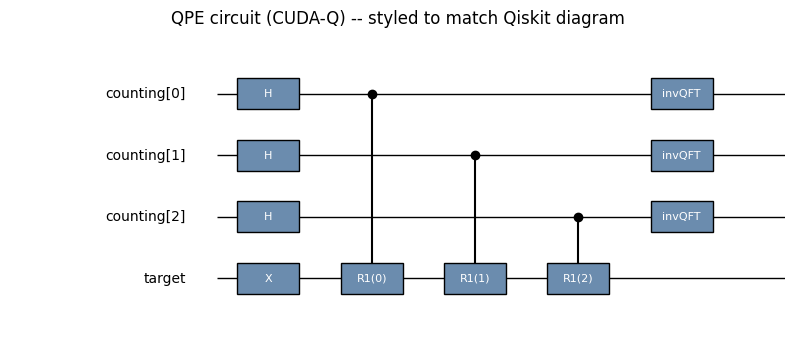

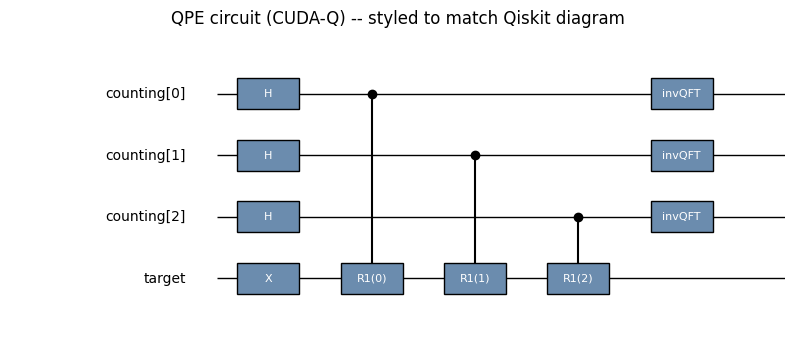

In [12]:
# CUDA-Q has no native matplotlib circuit renderer -- build a hand-drawn figure styled to
# visually resemble the Qiskit circuit diagram (wires, boxed gate labels, same qubit
# top-to-bottom order): counting[0..2] on top, target on bottom.

fig, ax = plt.subplots(figsize=(10, 4))
qubit_labels = [f"counting[{i}]" for i in range(N_COUNTING)] + ["target"]
n_wires = N_QUBITS
for i, label in enumerate(qubit_labels):
    y = n_wires - 1 - i
    ax.hlines(y, 0, 10, color="black", linewidth=1)
    ax.text(-0.3, y, label, ha="right", va="center", fontsize=10)

def draw_box(ax, x, y, text, width=0.6):
    ax.add_patch(plt.Rectangle((x - width / 2, y - 0.25), width, 0.5, fill=True,
                                facecolor="#6b8cae", edgecolor="black", zorder=3))
    ax.text(x, y, text, ha="center", va="center", color="white", fontsize=8, zorder=4)

x_pos = 0.5
for i in range(N_COUNTING):
    draw_box(ax, x_pos, n_wires - 1 - i, "H")
draw_box(ax, x_pos, 0, "X")
x_pos += 1
for k in range(N_COUNTING):
    y_ctrl = n_wires - 1 - k
    ax.plot(x_pos, y_ctrl, "o", color="black", zorder=3)
    ax.vlines(x_pos, 0, y_ctrl, color="black", zorder=2)
    draw_box(ax, x_pos, 0, f"R1({k})")
    x_pos += 1
draw_box(ax, x_pos, n_wires - 1, "invQFT")
draw_box(ax, x_pos, n_wires - 2, "invQFT")
draw_box(ax, x_pos, n_wires - 3, "invQFT")

ax.set_xlim(-2, x_pos + 1)
ax.set_ylim(-1, n_wires)
ax.axis("off")
ax.set_title("QPE circuit (CUDA-Q) -- styled to match Qiskit diagram")
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", bbox_inches="tight", dpi=150)
fig

In [13]:
# --- Cross-check (a): hand-built gate matrices in NumPy, identical to the Qiskit notebook ---
H = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])

def cp_matrix(angle):
    m = np.eye(4, dtype=complex)
    m[3, 3] = np.exp(1j * angle)
    return m

print("H gate:\n", np.round(H, 4))
for k in range(N_COUNTING):
    angle = LAMBDA * (2 ** k)
    print(f"\nControlled-R1({angle:.4f}) matrix:\n", np.round(cp_matrix(angle), 4))

# --- Cross-check (b): CUDA-Q's own statevector via get_state() ---
state = cudaq.get_state(qpe_state_kernel, N_COUNTING, LAMBDA)
state_arr = np.array(state)
print(f"\nCUDA-Q statevector length: {len(state_arr)} (expected {2 ** N_QUBITS})")
assert len(state_arr) == 2 ** N_QUBITS
print("Shape check PASSED.")

H gate:
 [[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Controlled-R1(0.7854) matrix:
 [[1.    +0.j     0.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     1.    +0.j     0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     1.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.    +0.j     0.7071+0.7071j]]

Controlled-R1(1.5708) matrix:
 [[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+1.j]]

Controlled-R1(3.1416) matrix:
 [[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]]

CUDA-Q statevector length: 16 (expected 16)
Shape check PASSED.


In [14]:
# --- Bit-order reversal: CUDA-Q indexes qubit 0 as MSB (leftmost); reverse to match qubit0=rightmost ---
def reverse_bitstring(bitstring):
    return bitstring[::-1]

def reversed_statevector(state_arr, n_qubits):
    reordered = {}
    for i, amp in enumerate(state_arr):
        cudaq_bitstring = format(i, f"0{n_qubits}b")        # CUDA-Q native: qubit0 = leftmost
        our_bitstring = reverse_bitstring(cudaq_bitstring)  # our convention: qubit0 = rightmost
        reordered[our_bitstring] = amp
    return reordered

def normalize_global_phase_dict(amp_dict):
    ordered_keys = sorted(amp_dict.keys(), key=lambda b: int(b, 2))  # ascending bitstring order
    phase = None
    for k in ordered_keys:
        if abs(amp_dict[k]) > 1e-9:
            phase = np.angle(amp_dict[k])
            break
    factor = np.exp(-1j * phase)
    return {k: v * factor for k, v in amp_dict.items()}

state = cudaq.get_state(qpe_state_kernel, N_COUNTING, LAMBDA)
state_arr = np.array(state)
reordered = reversed_statevector(state_arr, N_QUBITS)
normalized = normalize_global_phase_dict(reordered)

probs = {k: abs(v) ** 2 for k, v in normalized.items() if abs(v) ** 2 > 1e-9}
probs = dict(sorted(probs.items()))

print("Normalized amplitudes (nonzero only, our convention qubit0=rightmost):")
for k in sorted(normalized.keys(), key=lambda b: int(b, 2)):
    if abs(normalized[k]) > 1e-9:
        print(f"  |{k}>: {normalized[k]:.4f}")

print("\nStatevector probability dictionary (sorted by bitstring):")
for k, v in probs.items():
    print(f"  {k}: {v:.6f}")

Normalized amplitudes (nonzero only, our convention qubit0=rightmost):
  |1001>: 1.0000+0.0000j

Statevector probability dictionary (sorted by bitstring):
  1001: 1.000000


## Ordering-fix note
CUDA-Q's `get_state()` and `sample()` index qubit 0 as the most-significant (leftmost) bit.
The cell above explicitly reverses every bitstring key (`reverse_bitstring`) before computing
probabilities, so this notebook's output dictionaries use the same "qubit 0 = rightmost"
convention as the Qiskit notebook. The same reversal is applied again to the sampled counts below.


In [15]:
result = cudaq.sample(qpe_sample_kernel, N_COUNTING, LAMBDA, shots_count=SHOTS)

raw_counts = {}
for bitstring in result:
    raw_counts[bitstring] = result.count(bitstring)

# reverse each key to match the qubit0=rightmost convention shared with the Qiskit notebook
counts = {}
for k, v in raw_counts.items():
    rk = reverse_bitstring(k)
    counts[rk] = counts.get(rk, 0) + v

meas_probs = {k: v / SHOTS for k, v in sorted(counts.items())}
print("Measured counts (reversed to shared convention):", dict(sorted(counts.items())))
print("Measured probabilities:", meas_probs)

expected_bitstring = format(int(round(THETA * (2 ** N_COUNTING))), f"0{N_COUNTING}b")
print(f"\nExpected dominant outcome (hand-computed): '{expected_bitstring}' with probability ~1.0")
assert meas_probs.get(expected_bitstring, 0) > 0.99, "Measured distribution does not match hand-computed expectation"
print("Measurement self-check PASSED.")

Measured counts (reversed to shared convention): {'001': 10000}
Measured probabilities: {'001': 1.0}

Expected dominant outcome (hand-computed): '001' with probability ~1.0
Measurement self-check PASSED.


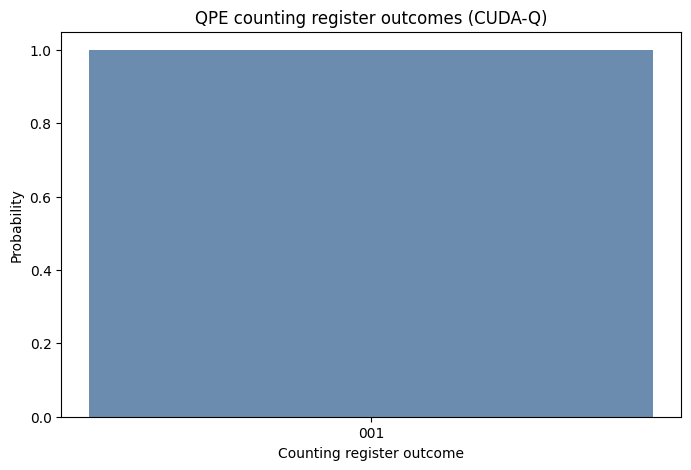

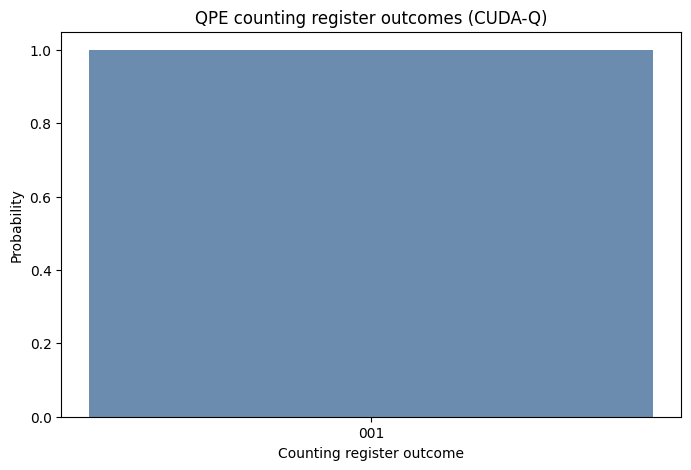

In [16]:
fig2, ax2 = plt.subplots(figsize=(8, 5))
keys = list(meas_probs.keys())
vals = [meas_probs[k] for k in keys]
ax2.bar(keys, vals, color="#6b8cae")
ax2.set_xlabel("Counting register outcome")
ax2.set_ylabel("Probability")
ax2.set_title("QPE counting register outcomes (CUDA-Q)")
fig2.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", bbox_inches="tight", dpi=150)
fig2

In [17]:
print(cudaq.draw(qpe_sample_kernel, N_COUNTING, LAMBDA))
# CUDA-Q kernels don't expose a direct .depth()/.count_ops() API like Qiskit;
# resource counts are read from the printed circuit diagram above (gate-by-gate listing).

     ╭───╮                                           ╭───╮                   »
q0 : ┤ h ├──────●──────────────────────────────────╳─┤ h ├──────●────────────»
     ├───┤      │                                  │ ╰───╯╭─────┴──────╮╭───╮»
q1 : ┤ h ├──────┼─────────────●────────────────────┼──────┤ r1(-1.571) ├┤ h ├»
     ├───┤      │             │                    │      ╰────────────╯╰───╯»
q2 : ┤ h ├──────┼─────────────┼────────────●───────╳─────────────────────────»
     ├───┤╭─────┴──────╮╭─────┴─────╮╭─────┴─────╮                           »
q3 : ┤ x ├┤ r1(0.7854) ├┤ r1(1.571) ├┤ r1(3.142) ├───────────────────────────»
     ╰───╯╰────────────╯╰───────────╯╰───────────╯                           »

################################################################################

                                  
───────●──────────────────────────
       │                          
───────┼─────────────●────────────
╭──────┴──────╮╭─────┴──────╮╭───╮
┤ r1(-0.7854) ├┤ r1(-1.571) ├┤ 

## Convention notes (restated)
- Qubit ordering: qubit 0 = rightmost bit -- reversal explicitly applied (CUDA-Q native is leftmost).
- Global phase: normalized so the first nonzero amplitude in ascending bitstring order
  (after reversal) is real and positive, using the same function as the Qiskit notebook.
- THETA = 1/8 chosen to be exactly representable in N_COUNTING = 3 bits, so the measured distribution
  is a single deterministic spike (no shot noise) -- this makes cross-checking against Qiskit unambiguous.


In [18]:
CUDAQ_RESULT = meas_probs
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'001': 1.0}


In [19]:
# --- Diff-check against Qiskit (paste QISKIT_RESULT here after running the Qiskit notebook) ---
# QISKIT_RESULT = {...}
# common_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT)
# max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in common_keys)
# print(f"Max probability delta: {max_delta:.2e}")
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance"

# Hand-computed sanity check (independent of simulation):
expected_theta_bits = format(int(round(THETA * (2 ** N_COUNTING))), f"0{N_COUNTING}b")
print(f"Hand-computed expected outcome: '{expected_theta_bits}' with probability ~1.0")
assert CUDAQ_RESULT.get(expected_theta_bits, 0) > 0.99
print("Final sanity check PASSED.")

Hand-computed expected outcome: '001' with probability ~1.0
Final sanity check PASSED.
